In [1]:
# Step 1: Load Shared Training Dataset

import pandas as pd
import numpy as np

from pathlib import Path

# Load original training features
X_train = pd.read_csv(
    "../data/processed/X_train_raw.csv"
)

# Load target labels
y_train = pd.read_csv(
    "../data/processed/y_train.csv"
).squeeze("columns")

# Verify dataset
print("Training features:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nClass distribution:")
print(y_train.value_counts())

print("\nMissing values:")
print(X_train.isnull().sum().sum())

print("\nFeature columns:")
print(X_train.columns.tolist())

Training features: (5634, 19)
Training labels: (5634,)

Class distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Missing values:
0

Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [2]:
# Step 2: Build Random Forest Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Numerical features
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SeniorCitizen"
]

# Categorical features
categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore"
        ), categorical_features)
    ]
)

# Build baseline Random Forest
rf_pipeline = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=1
        ))
    ]
)

print("Random Forest Pipeline Created!")
print(rf_pipeline)

Random Forest Pipeline Created!
Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges',
                                                   'SeniorCitizen']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
 

In [3]:
# Step 3: Train Baseline Random Forest

# Train the complete pipeline
rf_pipeline.fit(X_train, y_train)

print("Random Forest model trained successfully!")

# Get transformed feature names
feature_names = rf_pipeline.named_steps[
    "preprocessing"
].get_feature_names_out()

print("\nNumber of model features:", len(feature_names))

# Generate training predictions
train_predictions = rf_pipeline.predict(X_train)

# Generate churn probabilities
train_probabilities = rf_pipeline.predict_proba(X_train)[:, 1]

print("\nFirst 5 predicted classes:")
print(train_predictions[:5])

print("\nFirst 5 churn probabilities:")
print(train_probabilities[:5])

Random Forest model trained successfully!

Number of model features: 45

First 5 predicted classes:
[0 0 0 0 0]

First 5 churn probabilities:
[0.125 0.08  0.01  0.025 0.155]


In [4]:
# Step 4: Stratified 5-Fold Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_validate

# Same folds used for Logistic Regression
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Same evaluation metrics as Logistic Regression
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

# Evaluate Random Forest
cv_results = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

# Display results
print("=== BASELINE RANDOM FOREST ===")

for metric in scoring:
    scores = cv_results[f"test_{metric}"]

    print(
        f"{metric}: "
        f"{scores.mean():.4f} "
        f"(+/- {scores.std():.4f})"
    )

=== BASELINE RANDOM FOREST ===
accuracy: 0.7868 (+/- 0.0066)
precision: 0.6287 (+/- 0.0165)
recall: 0.4809 (+/- 0.0274)
f1: 0.5446 (+/- 0.0198)
roc_auc: 0.8218 (+/- 0.0117)
pr_auc: 0.6131 (+/- 0.0260)


In [5]:
# Step 5: Compare Standard and Weighted Random Forest

from sklearn.base import clone
from sklearn.model_selection import cross_validate
import pandas as pd

# Standard Random Forest
standard_rf = clone(rf_pipeline)

# Class-weighted Random Forest
weighted_rf = clone(rf_pipeline)

weighted_rf.set_params(
    model__class_weight="balanced"
)

models = {
    "Standard Random Forest": standard_rf,
    "Weighted Random Forest": weighted_rf
}

comparison_results = []

for name, model in models.items():

    results = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    comparison_results.append({
        "Model": name,
        "Accuracy": results["test_accuracy"].mean(),
        "Precision": results["test_precision"].mean(),
        "Recall": results["test_recall"].mean(),
        "F1": results["test_f1"].mean(),
        "ROC-AUC": results["test_roc_auc"].mean(),
        "Average Precision": results["test_pr_auc"].mean()
    })

comparison_df = pd.DataFrame(comparison_results)

print("=== RANDOM FOREST COMPARISON ===")
print(comparison_df.round(4).to_string(index=False))

=== RANDOM FOREST COMPARISON ===
                 Model  Accuracy  Precision  Recall     F1  ROC-AUC  Average Precision
Standard Random Forest    0.7868     0.6287  0.4809 0.5446   0.8218             0.6131
Weighted Random Forest    0.7863     0.6293  0.4749 0.5410   0.8208             0.6094


In [6]:
# Step 6: Random Forest Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from sklearn.base import clone

# Start with the standard Random Forest
tuning_pipeline = clone(standard_rf)

# Parameter combinations
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_leaf": [1, 5]
}

# Search using 5-fold stratified CV
grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=True
)

# Fit using training data only
grid_search.fit(X_train, y_train)

print("=== RANDOM FOREST TUNING RESULTS ===")

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1:")
print(round(grid_search.best_score_, 4))

print("\nTop 5 combinations:")
tuning_results = pd.DataFrame(grid_search.cv_results_)

print(
    tuning_results[
        [
            "param_model__n_estimators",
            "param_model__max_depth",
            "param_model__min_samples_leaf",
            "mean_test_score",
            "mean_train_score"
        ]
    ]
    .sort_values("mean_test_score", ascending=False)
    .head(5)
    .to_string(index=False)
)

=== RANDOM FOREST TUNING RESULTS ===

Best parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}

Best cross-validation F1:
0.5848

Top 5 combinations:
 param_model__n_estimators param_model__max_depth  param_model__min_samples_leaf  mean_test_score  mean_train_score
                       100                     10                              5         0.584770          0.678935
                       200                     10                              1         0.582355          0.776390
                       100                     10                              1         0.581497          0.776315
                       100                   None                              5         0.578980          0.706648
                       200                     10                              5         0.578812          0.679951


In [7]:
# Step 7: Tuned Random Forest - Nested CV Predictions

from sklearn.base import clone
from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV,
    cross_val_predict
)
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Same outer folds as earlier model comparisons
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Inner folds used only for parameter selection
inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

nested_search = GridSearchCV(
    estimator=clone(standard_rf),
    param_grid=param_grid,
    scoring="f1",
    cv=inner_cv,
    n_jobs=1,
    refit=True
)

# Out-of-fold probabilities from nested tuning
rf_cv_probs = cross_val_predict(
    nested_search,
    X_train,
    y_train,
    cv=outer_cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Compare thresholds
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

threshold_results = []

for threshold in thresholds:
    preds = (rf_cv_probs >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, preds, zero_division=0
        ),
        "Recall": recall_score(y_train, preds),
        "F1": f1_score(y_train, preds)
    })

rf_threshold_df = pd.DataFrame(threshold_results)

print("=== TUNED RANDOM FOREST THRESHOLD COMPARISON ===")
print(rf_threshold_df.round(4).to_string(index=False))

=== TUNED RANDOM FOREST THRESHOLD COMPARISON ===
 Threshold  Precision  Recall     F1
       0.2     0.4667  0.8676 0.6069
       0.3     0.5319  0.7639 0.6271
       0.4     0.5980  0.6468 0.6215
       0.5     0.6693  0.5077 0.5774
       0.6     0.7192  0.3358 0.4578
       0.7     0.7957  0.1980 0.3171


=== TOP 15 RANDOM FOREST FEATURES ===
                            Feature  Importance
                        num__tenure      0.1559
                  num__TotalCharges      0.1150
       cat__Contract_Month-to-month      0.0975
                num__MonthlyCharges      0.0725
             cat__OnlineSecurity_No      0.0646
   cat__InternetService_Fiber optic      0.0581
cat__PaymentMethod_Electronic check      0.0454
                cat__TechSupport_No      0.0445
             cat__Contract_Two year      0.0396
           cat__InternetService_DSL      0.0241
               cat__OnlineBackup_No      0.0155
            cat__OnlineSecurity_Yes      0.0146
           cat__PaperlessBilling_No      0.0131
               cat__TechSupport_Yes      0.0130
           cat__DeviceProtection_No      0.0126


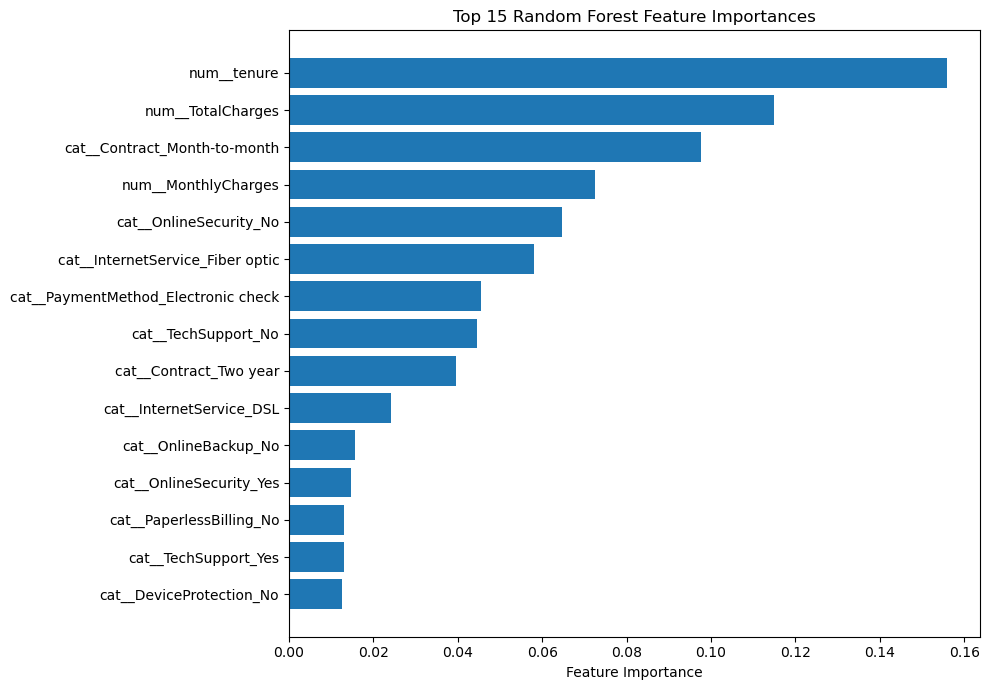

In [8]:
# Step 8: Random Forest Feature Importance

import pandas as pd

# Best model found through GridSearchCV
best_rf_pipeline = grid_search.best_estimator_

# Extract fitted preprocessing and model
rf_preprocessor = best_rf_pipeline.named_steps["preprocessing"]
rf_model = best_rf_pipeline.named_steps["model"]

# Feature names after one-hot encoding
feature_names = rf_preprocessor.get_feature_names_out()

# Feature importance scores
importances = rf_model.feature_importances_

# Create importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    by="Importance",
    ascending=False
)

print("=== TOP 15 RANDOM FOREST FEATURES ===")
print(importance_df.head(15).round(4).to_string(index=False))

# Plot top 15 features
import matplotlib.pyplot as plt

top_features = importance_df.head(15).iloc[::-1]

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()

plt.savefig(
    "../reports/random_forest_feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [9]:
# Step 9: Save Random Forest Model and Results

from pathlib import Path
import joblib
import pandas as pd
from sklearn.base import clone

# Create directories
model_dir = Path("../models")
reports_dir = Path("../reports")

model_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

# Refit the selected RF configuration on all training data
final_rf = clone(grid_search.best_estimator_)
final_rf.fit(X_train, y_train)

# Save complete fitted pipeline
joblib.dump(
    final_rf,
    model_dir / "random_forest.joblib"
)

# Save baseline and weighted comparison
comparison_df.to_csv(
    reports_dir / "random_forest_comparison.csv",
    index=False
)

# Save hyperparameter search results
pd.DataFrame(
    grid_search.cv_results_
).to_csv(
    reports_dir / "random_forest_tuning_results.csv",
    index=False
)

# Save threshold analysis
rf_threshold_df.to_csv(
    reports_dir / "random_forest_threshold_results.csv",
    index=False
)

# Save feature importance
importance_df.to_csv(
    reports_dir / "random_forest_feature_importance.csv",
    index=False
)

# Save provisional threshold configuration
rf_config = {
    "model": "Tuned Random Forest",
    "parameters": grid_search.best_params_,
    "threshold": 0.30,
    "status": "provisional",
    "selection_basis": "Highest exploratory F1 among tested thresholds"
}

joblib.dump(
    rf_config,
    model_dir / "random_forest_config.joblib"
)

print("Random Forest model saved successfully!")
print("Comparison results saved successfully!")
print("Tuning results saved successfully!")
print("Threshold results saved successfully!")
print("Feature importance saved successfully!")
print("Provisional configuration saved!")

Random Forest model saved successfully!
Comparison results saved successfully!
Tuning results saved successfully!
Threshold results saved successfully!
Feature importance saved successfully!
Provisional configuration saved!


In [10]:
# Step 10: Final Random Forest Validation

from pathlib import Path
import joblib
import pandas as pd

model_path = Path("../models/random_forest.joblib")
config_path = Path("../models/random_forest_config.joblib")

# Load saved model and configuration
saved_rf = joblib.load(model_path)
saved_config = joblib.load(config_path)

print("=== RANDOM FOREST FINAL VALIDATION ===")

print("\nModel loaded successfully!")
print("Pipeline steps:", list(saved_rf.named_steps.keys()))

print("\nModel parameters:")
print(saved_rf.named_steps["model"].get_params()["n_estimators"])
print(saved_rf.named_steps["model"].get_params()["max_depth"])
print(saved_rf.named_steps["model"].get_params()["min_samples_leaf"])

print("\nNumber of features:",
      len(saved_rf.named_steps["preprocessing"].get_feature_names_out()))

print("\nProvisional threshold:", saved_config["threshold"])

# Check saved model predictions
probabilities = saved_rf.predict_proba(X_train.head(5))[:, 1]

print("\nFirst 5 churn probabilities:")
print(probabilities)

print("\nSaved report files:")
for filename in [
    "random_forest_comparison.csv",
    "random_forest_tuning_results.csv",
    "random_forest_threshold_results.csv",
    "random_forest_feature_importance.csv"
]:
    path = Path("../reports") / filename
    print(filename, ":", "Found" if path.exists() else "Missing")

=== RANDOM FOREST FINAL VALIDATION ===

Model loaded successfully!
Pipeline steps: ['preprocessing', 'model']

Model parameters:
100
10
5

Number of features: 45

Provisional threshold: 0.3

First 5 churn probabilities:
[0.27545289 0.25856852 0.03859167 0.08190577 0.51540708]

Saved report files:
random_forest_comparison.csv : Found
random_forest_tuning_results.csv : Found
random_forest_threshold_results.csv : Found
random_forest_feature_importance.csv : Found


## Random Forest — Model Summary and Decision Log

### Objective

We developed Random Forest as an alternative to Logistic Regression for predicting customer churn. Random Forest combines multiple decision trees to capture nonlinear relationships and interactions between customer characteristics.

### Training and preprocessing

We used the shared training dataset containing 5,634 customers and 19 original features.

Categorical variables were one-hot encoded, while numerical features were retained without scaling. The final model used 45 numerical features.

We used 5-fold stratified cross-validation with `random_state=42`, keeping the 1,409-customer test dataset untouched.

### Baseline model results

| Metric | Standard RF | Weighted RF |
|---|---:|---:|
| Accuracy | 78.68% | 78.63% |
| Precision | 62.87% | 62.93% |
| Recall | 48.09% | 47.49% |
| F1-score | 54.46% | 54.10% |
| ROC-AUC | 82.18% | 82.08% |
| Average Precision | 61.31% | 60.94% |

Class weighting did not improve churn recall or F1-score, so we retained the standard Random Forest configuration for hyperparameter tuning.

### Hyperparameter tuning

We evaluated 12 parameter combinations using GridSearchCV.

The best configuration found was:

- `n_estimators = 100`
- `max_depth = 10`
- `min_samples_leaf = 5`

The best mean cross-validation F1-score during the search was **0.5848**, compared with **0.5446** for the untuned baseline.

Because the best score was selected from the same search, it may be optimistic as a generalization estimate.

### Classification threshold analysis

We examined thresholds from 0.20 to 0.70 using out-of-fold probability predictions from nested hyperparameter tuning.

A threshold of **0.30** achieved the highest observed F1-score among those evaluated:

- Precision: 53.19%
- Recall: 76.39%
- F1-score: 62.71%

This threshold is retained as a provisional candidate. Its performance remains exploratory because threshold selection used the same predictions summarized in the results.

### Feature importance

The most important individual encoded features were:

1. Tenure (0.1559)
2. TotalCharges (0.1150)
3. Month-to-month contract (0.0975)
4. MonthlyCharges (0.0725)
5. No online security (0.0646)

These impurity-based importance scores describe how heavily the model used features during tree splitting. They do not identify the causes or directions of churn risk.

### Model comparison

Logistic Regression with threshold 0.30 achieved an exploratory F1-score of 0.6346, compared with 0.6271 for tuned Random Forest at the same threshold.

Logistic Regression currently has a slight advantage, but neither configuration has been selected as the final group model.

### Limitations

- The held-out test set has not yet been evaluated.
- Threshold selection requires further validation.
- Impurity-based importance can be affected by correlated features.
- Churn probability calibration has not been assessed.
- The business costs of false positives and false negatives have not been quantified.

### Next steps

Compare Random Forest with Logistic Regression, Decision Tree, and XGBoost/LightGBM using consistent validation procedures.

The group will select the final model, evaluate it on the untouched test set, and perform high-risk customer profiling using suitable explanation methods.